# Exploration des données - Détection de Fraudes Financières
**Datasets** : PaySim (transactions mobiles) + IBM AML HI-Small (blanchiment réel)

In [1]:
import sys, os
sys.path.append('..')
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.figsize'] = (12, 5)
from config.config import PAYSIM_PATH, IBM_AML_TRANS, IBM_AML_ACCOUNTS

## 1. Dataset PaySim (streaming Kafka)

In [2]:
paysim = pd.read_csv(PAYSIM_PATH)
print(f'Dimensions : {paysim.shape}')
paysim.head(3)

Dimensions : (6362620, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0


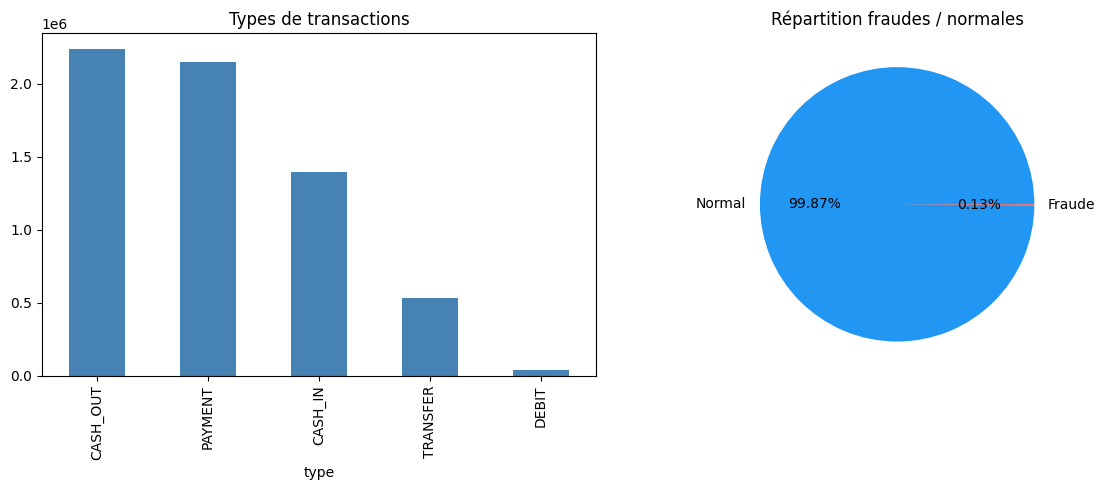

Total transactions : 6,362,620 | Fraudes : 8,213 (0.13%)


In [3]:
# Distribution des types de transactions
fig, axes = plt.subplots(1, 2)
paysim['type'].value_counts().plot(kind='bar', ax=axes[0], color='steelblue', title='Types de transactions')
fraud_counts = paysim['isFraud'].value_counts()
axes[1].pie(fraud_counts, labels=['Normal', 'Fraude'], autopct='%1.2f%%', colors=['#2196F3','#F44336'])
axes[1].set_title('Répartition fraudes / normales')
plt.tight_layout()
plt.show()
print(f"Total transactions : {len(paysim):,} | Fraudes : {paysim['isFraud'].sum():,} ({paysim['isFraud'].mean()*100:.2f}%)")

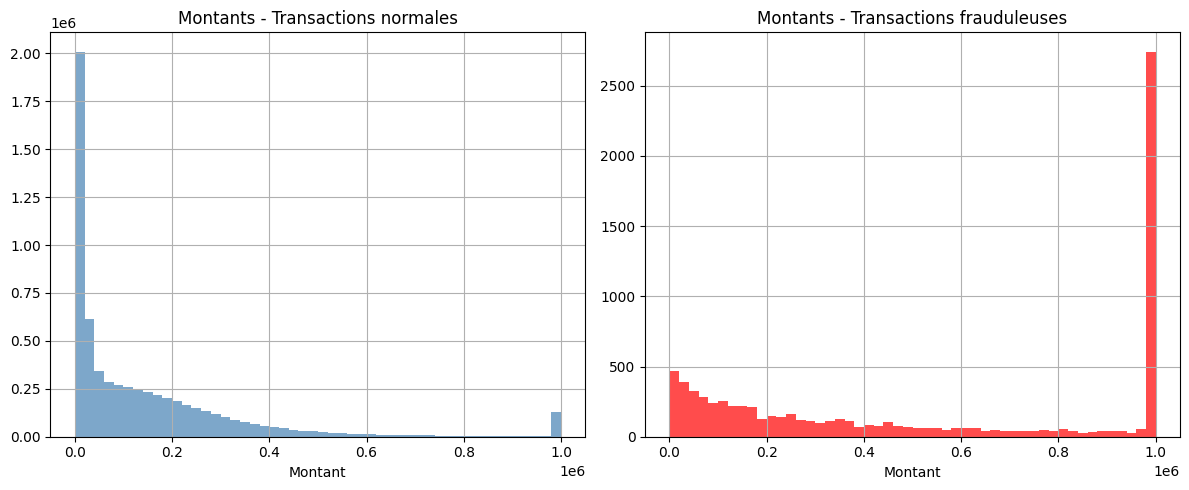

In [4]:
# Distribution des montants (fraudes vs normales)
import numpy as np
fig, axes = plt.subplots(1, 2)
paysim[paysim['isFraud']==0]['amount'].clip(upper=1e6).hist(bins=50, ax=axes[0], color='steelblue', alpha=0.7)
axes[0].set_title('Montants - Transactions normales'); axes[0].set_xlabel('Montant')
paysim[paysim['isFraud']==1]['amount'].clip(upper=1e6).hist(bins=50, ax=axes[1], color='red', alpha=0.7)
axes[1].set_title('Montants - Transactions frauduleuses'); axes[1].set_xlabel('Montant')
plt.tight_layout(); plt.show()

## 2. Dataset IBM AML HI-Small (graphe de blanchiment)

In [5]:
aml = pd.read_csv(IBM_AML_TRANS)
print(f'Dimensions : {aml.shape}')
print(f'Colonnes : {list(aml.columns)}')
aml.head(3)

Dimensions : (5078345, 11)
Colonnes : ['Timestamp', 'From Bank', 'Account', 'To Bank', 'Account.1', 'Amount Received', 'Receiving Currency', 'Amount Paid', 'Payment Currency', 'Payment Format', 'Is Laundering']


,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
0,2022/09/01 00:20,10,8000EBD30,10,8000EBD30,3697.34,US Dollar,3697.34,US Dollar,Reinvestment,0
1,2022/09/01 00:20,3208,8000F4580,1,8000F5340,0.01,US Dollar,0.01,US Dollar,Cheque,0
2,2022/09/01 00:00,3209,8000F4670,3209,8000F4670,14675.57,US Dollar,14675.57,US Dollar,Reinvestment,0


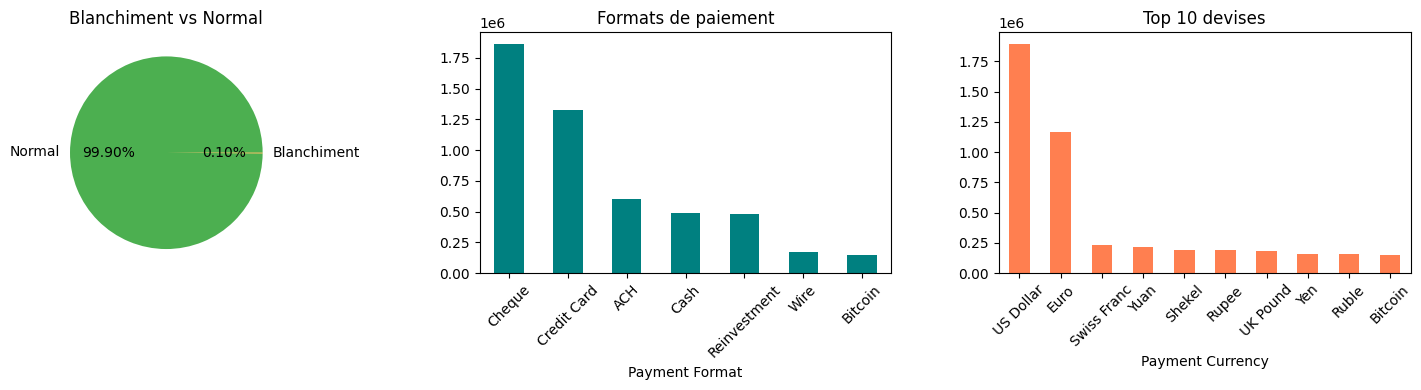

Transactions de blanchiment : 5,177 (0.10%)


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))

launder_counts = aml['Is Laundering'].value_counts()
axes[0].pie(launder_counts, labels=['Normal','Blanchiment'], autopct='%1.2f%%', colors=['#4CAF50','#FF9800'])
axes[0].set_title('Blanchiment vs Normal')

aml['Payment Format'].value_counts().plot(kind='bar', ax=axes[1], color='teal', title='Formats de paiement')
axes[1].tick_params(axis='x', rotation=45)

aml['Payment Currency'].value_counts().head(10).plot(kind='bar', ax=axes[2], color='coral', title='Top 10 devises')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout(); plt.show()
print(f"Transactions de blanchiment : {launder_counts.get(1,0):,} ({launder_counts.get(1,0)/len(aml)*100:.2f}%)")

In [7]:
# Statistiques globales
print('=== RÉSUMÉ DES DONNÉES ===')
print(f'PaySim  : {len(paysim):>10,} transactions | {paysim["isFraud"].sum():>6,} fraudes ({paysim["isFraud"].mean()*100:.2f}%)')
print(f'IBM AML : {len(aml):>10,} transactions | {aml["Is Laundering"].sum():>6,} blanchiments ({aml["Is Laundering"].mean()*100:.2f}%)')
nb_comptes = pd.concat([aml['Account'], aml['Account.1']]).nunique()
print(f'Comptes uniques IBM AML : {nb_comptes:,}')

=== RÉSUMÉ DES DONNÉES ===
PaySim  :  6,362,620 transactions |  8,213 fraudes (0.13%)
IBM AML :  5,078,345 transactions |  5,177 blanchiments (0.10%)


Comptes uniques IBM AML : 515,080
